# 04 — Financial Inclusion EDA & Demographic Gap (Integrated with Notebook 03)

**Owner:** Rafa (`rrrafaa`) | **Data:** World Bank Global Findex Indonesia survey 2024  
**Prerequisite:** Notebook **03** must have completed with **ALL INTEGRATION CHECKS PASSED** and its four required output files must be available privately.

**NEW DATA FLOW:** `03_cleaning_integration.ipynb` → validated private respondent dataset + canonical weighted KPI aggregates + QA + manifest → **this Notebook 04** → analysis charts + review-ready Rafa aggregates → Notebook 06 → Looker Studio.

**Important:** This notebook **does not read the raw ZIP** or repeat the demographic cleaning from scratch. Visualizations use the **canonical aggregate KPI table produced by Notebook 03**. For an independent check, it recalculates rates against the **private integrated respondent dataset** and requires exact agreement (within CSV export rounding). Do not share or commit respondent-level data.

**Run on:** Google Colab (recommended) or local Jupyter. The notebook starts with zero saved execution outputs: run every cell and inspect the results before saving an executed copy to GitHub.

## 1. Load the PRIVATE results of Notebook 03 (Google Drive or local)

Notebook 03 produces these files in `data/processed/` and, if its final cell used `SAVE_TO_PRIVATE_DRIVE = True`, in **`MyDrive/Financial_Inclusion_Private/processed/`**:

- `integrated_respondents_private.csv` (**private** person-level file; never upload to public GitHub)
- `dashboard_kpi_aggregates.csv` (validated KPI for dashboard)
- `integration_quality_checks.csv` (all rows should be `PASS`)
- `integration_manifest.json` (original source checksum and shape)

**Colab:** sign in with the **same Google account** that ran Notebook 03. The cell mounts Google Drive if necessary.  
**Local:** put these four files in your locally cloned repository's `data/processed/` folder.  
**Other folder:** set `CUSTOM_PROCESSED_DIR` to its absolute path in the code cell.

If files are not found in either location, Colab offers an upload dialog for these **four processed outputs**. Do not upload the original ZIP to Notebook 04.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO_NAME = "Indonesia-Financial-Inclusion-Digital-Finance-Analytics"
REPO_URL = f"https://github.com/rrrafaa/{REPO_NAME}.git"
IN_COLAB = "google.colab" in sys.modules

# Optional: set an absolute path to a DIFFERENT private output directory.
CUSTOM_PROCESSED_DIR = None
NEEDED = (
    "integrated_respondents_private.csv",
    "dashboard_kpi_aggregates.csv",
    "integration_quality_checks.csv",
    "integration_manifest.json",
)
EXPECTED_SOURCE_SHA = "fc50f0a843e289a3b9784ac81dce1018a8195388608575e6c8315c195073a64c"
EXPECTED_SOURCE_CSV_SHA = "77a50e351c16946ad107c08494efe9e8972ba628168fa385b771695971710093"

def locate_repo():
    options = [Path.cwd(), *Path.cwd().parents]
    if IN_COLAB:
        options.append(Path("/content") / REPO_NAME)
    for folder in options:
        if (folder / "data" / "raw" / "README.md").is_file():
            return folder
    if IN_COLAB:
        folder = Path("/content") / REPO_NAME
        if not folder.exists():
            subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(folder)], check=True)
        if (folder / "data" / "raw" / "README.md").is_file():
            return folder
    raise FileNotFoundError("Clone the GitHub repository and run Jupyter from within its folder.")

ROOT = locate_repo()
LOCAL_PROCESSED = ROOT / "data" / "processed"
LOCAL_PROCESSED.mkdir(parents=True, exist_ok=True)
PRIVATE_DRIVE = Path("/content/drive/MyDrive/Financial_Inclusion_Private/processed")

def complete(folder):
    return folder.is_dir() and all((folder / filename).is_file() for filename in NEEDED)

choices = []
if CUSTOM_PROCESSED_DIR:
    choices.append(Path(CUSTOM_PROCESSED_DIR).expanduser())
if IN_COLAB:
    choices.append(PRIVATE_DRIVE)
choices.append(LOCAL_PROCESSED)

DATA_DIR = next((folder for folder in choices if complete(folder)), None)
if DATA_DIR is None and IN_COLAB:
    from google.colab import drive
    print("Connecting the private Google Drive used by Notebook 03...")
    drive.mount("/content/drive")
    DATA_DIR = next((folder for folder in choices if complete(folder)), None)

if DATA_DIR is None and IN_COLAB:
    from google.colab import files
    print("Notebook 03 outputs were not found. Upload these FOUR private files:")
    print(*NEEDED, sep="\n - ")
    uploaded = files.upload()
    missing = set(NEEDED) - set(uploaded)
    if missing:
        raise FileNotFoundError(f"Missing output files: {sorted(missing)}")
    for filename in NEEDED:
        (LOCAL_PROCESSED / filename).write_bytes(uploaded[filename])
    DATA_DIR = LOCAL_PROCESSED

if DATA_DIR is None:
    raise FileNotFoundError(
        "Required Notebook 03 outputs are absent. Place all four files in data/processed/ "
        "or configure CUSTOM_PROCESSED_DIR."
    )

manifest = json.loads((DATA_DIR / "integration_manifest.json").read_text(encoding="utf-8"))
qa = pd.read_csv(DATA_DIR / "integration_quality_checks.csv")
assert manifest.get("source_zip_sha256") == EXPECTED_SOURCE_SHA, "Notebook 03 used a different ZIP."
assert manifest.get("source_csv_sha256") == EXPECTED_SOURCE_CSV_SHA, "Notebook 03 CSV checksum differs."
assert manifest.get("qa_passed") is True, "Notebook 03 QA flag was not PASS."
assert len(qa) >= 14 and qa["status"].eq("PASS").all(), "Notebook 03 has failed or missing QA checks."
assert manifest.get("raw_shape") == [1068, 199], "Unexpected source data shape."

d = pd.read_csv(DATA_DIR / "integrated_respondents_private.csv", low_memory=False)
canonical = pd.read_csv(DATA_DIR / "dashboard_kpi_aggregates.csv")
assert list(d.shape) == manifest["clean_shape"], "Integrated respondent file and manifest disagree."
assert len(d) == 1068 and set(d["year"].dropna().unique()) == {2024}
assert "wpid_random" not in d.columns, "Source respondent ID must not be used in this workflow."

print("Notebook 03 integration: VERIFIED")
print("Private input directory:", DATA_DIR)
print("Integrated observations:", len(d), "| Canonical KPI rows:", len(canonical))
print("Quality checks:", len(qa), "PASS")
print("No raw ZIP is required for this notebook.")

Connecting the private Google Drive used by Notebook 03...
Mounted at /content/drive
Notebook 03 integration: VERIFIED
Private input directory: /content/drive/MyDrive/Financial_Inclusion_Private/processed
Integrated observations: 1068 | Canonical KPI rows: 140
Quality checks: 14 PASS
No raw ZIP is required for this notebook.


## 2. Use the same category definitions established by Notebook 03

All subgroup labels are already present in `integrated_respondents_private.csv` and must **not** be recoded independently. The single missing education response remains missing and is **excluded** from education comparisons. The source dataset is never displayed row-by-row.

In [2]:
DIMENSION_ORDER = {
    "gender": ["Female", "Male"],
    "income_quintile": ["Q1 - lowest", "Q2", "Q3", "Q4", "Q5 - highest"],
    "education": ["Primary or less", "Secondary", "Tertiary or more"],
    "age_group": ["15-24", "25-34", "35-44", "45-54", "55+"],
    "residence": ["Rural", "Urban"],
    "internet_group": ["Non-internet user", "Internet user"],
}
INDICATORS = {
    "account": "Owns an account",
    "account_fin": "Financial institution account",
    "account_mob": "Mobile money account",
    "anydigpayment": "Digital payment use",
    "saved": "Saved money",
    "borrowed": "Borrowed money",
}
for column in set(INDICATORS) | {"internet_use", "wgt", "year", *DIMENSION_ORDER}:
    assert column in d.columns, f"Missing integrated column: {column}"
for indicator in set(INDICATORS) | {"internet_use"}:
    assert d[indicator].dropna().isin([0, 1]).all(), f"Invalid indicator code: {indicator}"
assert d["wgt"].notna().all() and d["wgt"].gt(0).all()
assert d["education"].isna().sum() == 1
for dimension, labels in DIMENSION_ORDER.items():
    unexpected = set(d[dimension].dropna().unique()) - set(labels)
    assert not unexpected, f"Unmapped labels in {dimension}: {unexpected}"
assert not d["age_group"].isna().any(), "Age groups must be complete."

expected_cols = {
    "metric", "metric_label", "dimension", "category", "sort_order",
    "numerator_wgt", "denominator_wgt", "rate_pct", "n_valid", "n_yes"
}
assert expected_cols <= set(canonical.columns)
assert canonical[["metric", "dimension", "category"]].notna().all().all()
assert canonical["n_valid"].ge(30).all(), "Published aggregates contain small cells."
assert canonical["rate_pct"].between(0, 100).all()
assert not canonical.duplicated(["metric", "dimension", "category"]).any()
assert set(canonical["metric"]) == set(INDICATORS) | {"internet_use"}
assert len(canonical) == 140, "Notebook 03 KPI table shape has changed; review before proceeding."

print("Canonical categories validated; education missingness retained.")
print("No respondent-level preview will be displayed.")

Canonical categories validated; education missingness retained.
No respondent-level preview will be displayed.


## 3. Recalculate and cross-check every KPI with Notebook 03

Each row of the 140-row canonical table is checked against an **independent computation** on the private integrated respondent data:

\[
\text{Weighted rate (\%)}=100\times \frac{\sum_i w_i\,\mathbb{1}(y_i=1)}{\sum_i w_i}\quad\text{over valid answers only.}
\]

**Important:** We compare unrounded numerators, denominators, rates and sample sizes. The CSV from Notebook 03 is rounded to 8 decimal places, so the comparison allows tiny floating-point export tolerances. **Stop if this cell fails**; do not use the resulting charts for the dashboard.

In [3]:
def weighted_components(frame, indicator):
    valid = frame.loc[frame[indicator].isin([0, 1]) & frame["wgt"].gt(0)]
    if valid.empty:
        raise ValueError(f"No valid observations for {indicator}")
    numerator = float((valid[indicator] * valid["wgt"]).sum())
    denominator = float(valid["wgt"].sum())
    return {
        "numerator_wgt": numerator,
        "denominator_wgt": denominator,
        "rate_pct": 100.0 * numerator / denominator,
        "n_valid": int(len(valid)),
        "n_yes": int(valid[indicator].eq(1).sum())
    }

checked = []
for row in canonical.itertuples(index=False):
    if row.dimension == "national":
        frame = d
    else:
        if row.dimension not in DIMENSION_ORDER:
            raise ValueError(f"Unexpected aggregation dimension: {row.dimension}")
        frame = d.loc[d[row.dimension].eq(row.category)]
    expected = weighted_components(frame, row.metric)
    ok = (
        int(row.n_valid) == expected["n_valid"]
        and int(row.n_yes) == expected["n_yes"]
        and abs(float(row.numerator_wgt) - expected["numerator_wgt"]) <= 0.00001
        and abs(float(row.denominator_wgt) - expected["denominator_wgt"]) <= 0.00001
        and abs(float(row.rate_pct) - expected["rate_pct"]) <= 0.00001
    )
    checked.append({
        "metric": row.metric, "dimension": row.dimension, "category": row.category,
        "status": "PASS" if ok else "FAIL",
        "recomputed_rate_pct": expected["rate_pct"],
        "canonical_rate_pct": float(row.rate_pct),
        "n_valid": expected["n_valid"]
    })

validation = pd.DataFrame(checked)
if not validation.status.eq("PASS").all():
    display(validation.loc[validation.status.eq("FAIL")])
    raise AssertionError("Notebook 04 and Notebook 03 do not match. STOP dashboard work.")
assert len(validation) == 140
print("ALL 140 KPI CROSS-CHECKS PASSED.")
print("Source: Notebook 03 integrated respondent data + canonical weighted aggregates")

def by_group(dimension, indicator="account"):
    """Get the approved, sorted Notebook 03 weighted KPI table (not an average of group rates)."""
    if dimension not in DIMENSION_ORDER:
        raise ValueError(f"Unknown demographic dimension: {dimension}")
    part = canonical.loc[
        canonical["metric"].eq(indicator) & canonical["dimension"].eq(dimension)
    ].copy().sort_values("sort_order")
    return part.rename(columns={
        "category": "group",
        "denominator_wgt": "weight_total"
    }).assign(small_n_warning=lambda x: x.n_valid < 30)

overview = (
    canonical.loc[
        canonical["dimension"].eq("national")
        & canonical["metric"].isin(INDICATORS)
    ].copy()
    .assign(label=lambda x: x["metric"].map(INDICATORS))
)
overview = overview[["metric", "label", "rate_pct", "n_valid",
                     "numerator_wgt", "denominator_wgt"]]
overview["sort_order"] = overview["metric"].map({k: i for i, k in enumerate(INDICATORS)})
overview = overview.sort_values("sort_order").drop(columns="sort_order").reset_index(drop=True)
display(overview.round(3))
assert 50 < overview.loc[overview.metric.eq("account"), "rate_pct"].iloc[0] < 65

ALL 140 KPI CROSS-CHECKS PASSED.
Source: Notebook 03 integrated respondent data + canonical weighted aggregates


,metric,label,rate_pct,n_valid,numerator_wgt,denominator_wgt
0,account,Owns an account,56.328,1068,601.581,1068.0
1,account_fin,Financial institution account,52.392,1068,559.546,1068.0
2,account_mob,Mobile money account,22.013,1068,235.098,1068.0
3,anydigpayment,Digital payment use,42.693,1068,455.964,1068.0
4,saved,Saved money,52.995,1068,565.984,1068.0
5,borrowed,Borrowed money,47.636,1068,508.753,1068.0


## 4. National financial inclusion overview

Use the **canonical Notebook 03 weighted rates** for the national KPIs, not respondent-level previews or a mean of subgroup percentages.

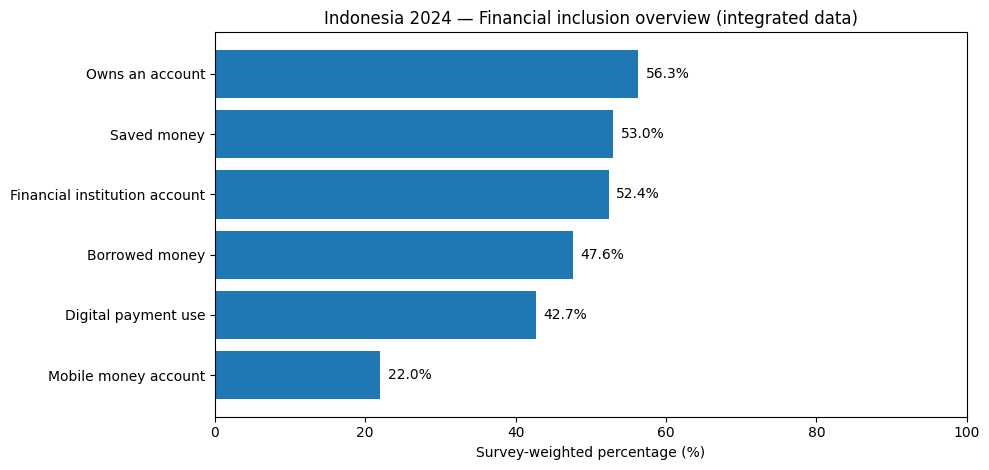

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.8))
tmp = overview.sort_values("rate_pct")
ax.barh(tmp["label"], tmp["rate_pct"])
ax.set_xlim(0, 100)
ax.set_xlabel("Survey-weighted percentage (%)")
ax.set_title("Indonesia 2024 — Financial inclusion overview (integrated data)")
for i, v in enumerate(tmp["rate_pct"]):
    ax.text(min(v + 1, 97), i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.show()

## 5. Account ownership by income quintile

Show Q1–Q5 in the agreed order. Compare **Q5 minus Q1** and separately distinguish the observed maximum–minimum difference (which may involve Q3). Report gaps in **percentage points**, not relative percent.

,group,rate_pct,n_valid,small_n_warning
10,Q1 - lowest,46.425,210,False
11,Q2,50.406,199,False
12,Q3,46.203,210,False
13,Q4,60.590,205,False
14,Q5 - highest,78.002,244,False


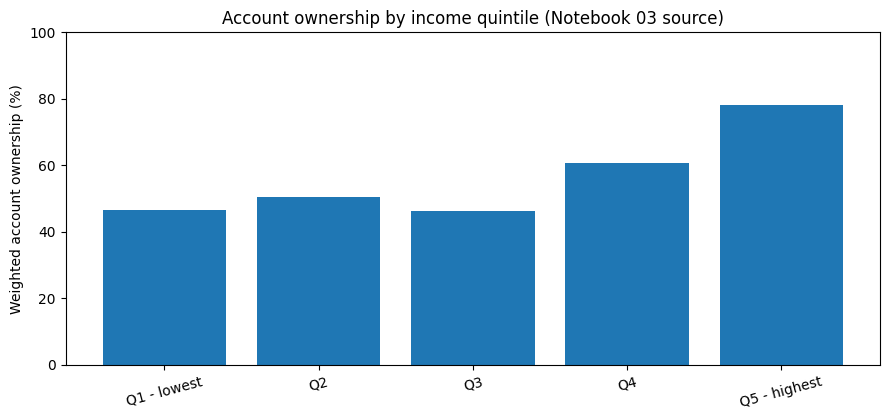

Income Q5 − Q1 gap: 31.577 percentage points
Observed max − min across income quintiles: 31.799 pp


In [5]:
income = by_group("income_quintile", "account")
display(income[["group", "rate_pct", "n_valid", "small_n_warning"]].round(3))
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.bar(income["group"], income["rate_pct"])
ax.set(ylim=(0, 100), ylabel="Weighted account ownership (%)",
       title="Account ownership by income quintile (Notebook 03 source)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
q1 = float(income.loc[income.group.eq("Q1 - lowest"), "rate_pct"].iloc[0])
q5 = float(income.loc[income.group.eq("Q5 - highest"), "rate_pct"].iloc[0])
print(f"Income Q5 − Q1 gap: {q5 - q1:.3f} percentage points")
print(f"Observed max − min across income quintiles: {income.rate_pct.max() - income.rate_pct.min():.3f} pp")
assert q5 > q1

## 6. Account ownership by gender, education, age group and residence

The one respondent with unknown education is **not** a plotted category. All displayed groups come from the **Notebook 03 approved aggregations**, with at least 30 valid respondents (small groups require additional caution even when above 30).

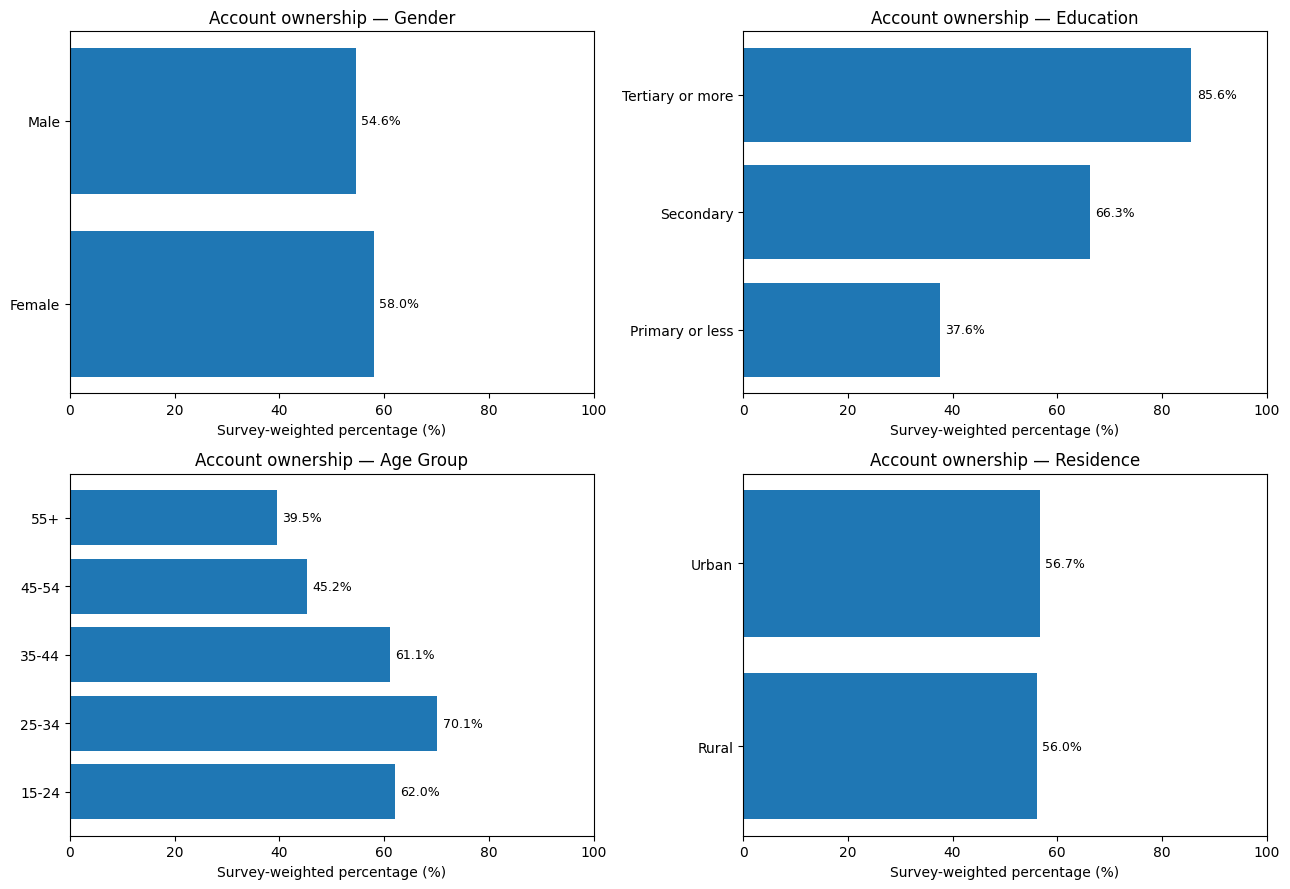

,dimension,group,rate_pct,n_valid,small_n_warning
0,income_quintile,Q1 - lowest,46.425,210,False
1,income_quintile,Q2,50.406,199,False
2,income_quintile,Q3,46.203,210,False
3,income_quintile,Q4,60.590,205,False
4,income_quintile,Q5 - highest,78.002,244,False
5,gender,Female,58.031,557,False
6,gender,Male,54.639,511,False
7,education,Primary or less,37.638,380,False
8,education,Secondary,66.268,646,False
9,education,Tertiary or more,85.607,41,False


Small cells (<30 unweighted valid respondents): 0
Note: tertiary education has only 41 unweighted respondents; treat estimates cautiously.


In [6]:
dimensions = ["gender", "education", "age_group", "residence"]
tables = []
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, dim in zip(axes.flat, dimensions):
    t = by_group(dim, "account")
    tables.append(t)
    ax.barh(t["group"], t["rate_pct"])
    ax.set_xlim(0, 100)
    ax.set_title("Account ownership — " + dim.replace("_", " ").title())
    ax.set_xlabel("Survey-weighted percentage (%)")
    for i, v in enumerate(t["rate_pct"]):
        ax.text(min(v + 1, 97), i, f"{v:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.show()
segments = pd.concat([income, *tables], ignore_index=True)
assert not segments["group"].isna().any()
display(segments[["dimension", "group", "rate_pct", "n_valid", "small_n_warning"]].round(3))
print("Small cells (<30 unweighted valid respondents):", int(segments.small_n_warning.sum()))
print("Note: tertiary education has only 41 unweighted respondents; treat estimates cautiously.")

## 7. Compare different financial inclusion indicators by demographic group

The original indicators **may overlap**, so never stack them to 100%. Values below come from the canonical Notebook 03 aggregates. The chart compares the same indicators across genders for descriptive insight.

,dimension,group,metric,rate_pct,n_valid
0,gender,Female,account,58.031,557
1,gender,Male,account,54.639,511
2,gender,Female,account_fin,53.881,557
3,gender,Male,account_fin,50.915,511
4,gender,Female,account_mob,19.878,557
5,gender,Male,account_mob,24.131,511
6,gender,Female,anydigpayment,43.481,557
7,gender,Male,anydigpayment,41.912,511
8,gender,Female,saved,56.463,557
9,gender,Male,saved,49.555,511


group,Female,Male
Owns an account,58.03,54.64
Financial institution account,53.88,50.91
Mobile money account,19.88,24.13
Digital payment use,43.48,41.91
Saved money,56.46,49.56
Borrowed money,45.39,49.86


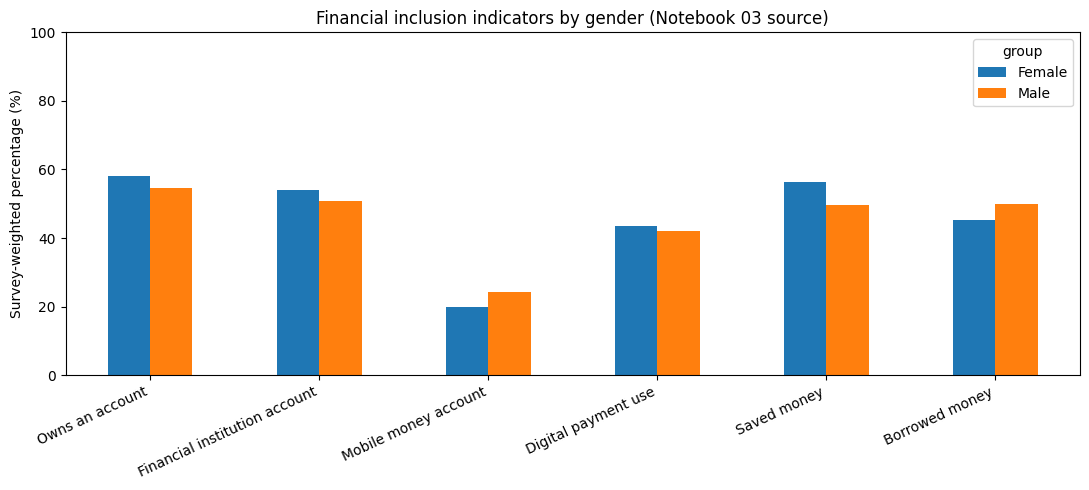

In [7]:
cross = pd.concat(
    [by_group(dim, indicator) for dim in ["gender", "income_quintile", "residence"]
     for indicator in INDICATORS],
    ignore_index=True
)
display(cross[["dimension", "group", "metric", "rate_pct", "n_valid"]].head(18).round(3))
pivot = (
    cross.loc[cross.dimension.eq("gender")]
    .pivot(index="metric", columns="group", values="rate_pct")
    .reindex(index=list(INDICATORS))
)
pivot.index = [INDICATORS[k] for k in pivot.index]
display(pivot.round(2))
ax = pivot.plot(kind="bar", figsize=(11, 5))
ax.set_ylim(0, 100)
ax.set_ylabel("Survey-weighted percentage (%)")
ax.set_title("Financial inclusion indicators by gender (Notebook 03 source)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 8. Financial inclusion gap table and final consistency tests

For each demographic dimension, show the **largest observed descriptive gap** among approved groups. This differs from a policy-specific Q5–Q1 comparison. These are **not** significance tests.

In [8]:
gap_rows = []
for dim in dimensions + ["income_quintile"]:
    t = by_group(dim, "account")
    valid = t.loc[~t["small_n_warning"] & t["rate_pct"].notna()]
    if len(valid) < 2:
        continue
    hi = valid.loc[valid.rate_pct.idxmax()]
    lo = valid.loc[valid.rate_pct.idxmin()]
    gap_rows.append({
        "dimension": dim, "highest_group": hi.group, "lowest_group": lo.group,
        "max_rate_pct": float(hi.rate_pct),
        "min_rate_pct": float(lo.rate_pct),
        "gap_pp": float(hi.rate_pct - lo.rate_pct)
    })
gaps = pd.DataFrame(gap_rows).sort_values("gap_pp", ascending=False).reset_index(drop=True)
display(gaps.round(3))
national_source = float(overview.loc[overview.metric.eq("account"), "rate_pct"].iloc[0])
national_recalc = weighted_components(d, "account")["rate_pct"]
assert abs(national_source - national_recalc) < 1e-5
assert not segments.rate_pct.dropna().gt(100).any()
print(f"National weighted account ownership: {national_source:.3f}% (matches Notebook 03)")
print("Verified survey respondents:", len(d), "| Year:", d.year.unique().tolist())
print("KPI cross-check status: ALL PASS")

,dimension,highest_group,lowest_group,max_rate_pct,min_rate_pct,gap_pp
0,education,Tertiary or more,Primary or less,85.607,37.638,47.969
1,income_quintile,Q5 - highest,Q3,78.002,46.203,31.799
2,age_group,25-34,55+,70.135,39.519,30.615
3,gender,Female,Male,58.031,54.639,3.392
4,residence,Urban,Rural,56.666,56.030,0.636


National weighted account ownership: 56.328% (matches Notebook 03)
Verified survey respondents: 1068 | Year: [2024]
KPI cross-check status: ALL PASS


## 9. Save approved Rafa aggregates for Notebook 06

Five **aggregate-only** outputs are generated from the canonical Notebook 03 figures. If Notebook 03 results were loaded from **Google Drive**, these four files are saved to the same **private** Drive folder; otherwise, they are saved to local `data/processed/`.

The individual-level dataset remains private. **Do not push CSV data to the public repository by force**. Before uploading aggregates to Google Sheets / Looker Studio, both analysts should confirm the final metrics and any small-cell disclosure rules.

In [9]:
# Save results alongside validated Notebook 03 outputs; no public GitHub upload happens here.
out = DATA_DIR if DATA_DIR == PRIVATE_DRIVE else LOCAL_PROCESSED
out.mkdir(parents=True, exist_ok=True)
exports = {
    "person1_overview_kpis.csv": overview,
    "person1_account_segments.csv": segments,
    "person1_cross_metrics.csv": cross,
    "person1_gap_summary.csv": gaps,
    "person1_notebook03_validation.csv": validation
}
for filename, frame in exports.items():
    frame.to_csv(out / filename, index=False, float_format="%.8f")
print("Saved five approved analysis/validation tables in:", out)
for filename in exports:
    print(" -", filename)
print("Do not commit respondent-level data or source ZIP files.")

Saved five approved analysis/validation tables in: /content/drive/MyDrive/Financial_Inclusion_Private/processed
 - person1_overview_kpis.csv
 - person1_account_segments.csv
 - person1_cross_metrics.csv
 - person1_gap_summary.csv
 - person1_notebook03_validation.csv
Do not commit respondent-level data or source ZIP files.


## 10. Interpretasi Akhir EDA — Financial Inclusion Indonesia 2024 (Terintegrasi dengan Notebook 03)

> **Status analisis: VALIDATED / siap direview bersama sebelum tahap dashboard.** Seluruh **14 quality checks** dari Notebook 03 berstatus **PASS**, dan Notebook 04 berhasil mencocokkan ulang **140 dari 140 baris KPI agregat** terhadap dataset bersih privat dari Notebook 03 (`ALL 140 KPI CROSS-CHECKS PASSED.`). Dengan demikian, seluruh angka di bawah ini merujuk pada **hasil eksekusi integrasi terbaru**, bukan hanya asumsi atau salinan interpretasi saat analisis masih mengambil ZIP mentah.

**Lingkup:** Indonesia, survei Global Findex tahun **2024**; **1.068 responden**; angka persentase dihitung menggunakan bobot survei `wgt` dan penyebut jawaban yang valid. Selisih antarkelompok dinyatakan dalam **percentage points (pp / poin persentase)**. Data ini **cross-sectional**, sehingga hubungan yang terlihat bersifat **deskriptif, bukan kausal**.

### 10.1 Gambaran nasional: akses rekening dan perilaku keuangan

| Indikator | Weighted rate (hasil terbaru) | Makna ringkas |
|---|---:|---|
| Memiliki rekening apa pun — `account` | **56,328%** | Sekitar 56 dari setiap 100 orang dalam populasi yang direpresentasikan survei memiliki rekening |
| Rekening lembaga keuangan — `account_fin` | **52,392%** | Akses ke rekening lembaga keuangan |
| Akun mobile money — `account_mob` | **22,013%** | Kepemilikan akun uang seluler |
| Menggunakan pembayaran digital — `anydigpayment` | **42,693%** | Penggunaan pembayaran digital sesuai definisi survei |
| Menabung — `saved` | **52,995%** | Aktivitas menabung menurut indikator survei |
| Meminjam — `borrowed` | **47,636%** | Aktivitas meminjam menurut indikator survei |

**Interpretasi:** Kepemilikan rekening secara umum sudah melebihi separuh populasi dewasa yang direpresentasikan survei, tetapi masih ada porsi yang belum memiliki rekening. Pemakaian pembayaran digital (42,693%) lebih rendah daripada kepemilikan rekening (56,328%). **Kedua indikator dapat tumpang tindih dan memiliki definisi pengukuran berbeda**: selisihnya **tidak boleh** disebut sebagai *conversion rate*, jumlah orang yang gagal menggunakan pembayaran digital, atau hubungan sebab-akibat. Kepemilikan mobile money (22,013%) juga tidak boleh dijumlahkan dengan rekening lembaga keuangan karena kategorinya dapat beririsan.

### 10.2 Kesenjangan berdasarkan kuintil pendapatan

| Kuintil | Kepemilikan rekening (weighted) | Jumlah responden valid (`n`) |
|---|---:|---:|
| Q1 — terendah | 46,425% | 210 |
| Q2 | 50,406% | 199 |
| Q3 | 46,203% | 210 |
| Q4 | 60,590% | 205 |
| Q5 — tertinggi | **78,002%** | 244 |

**Interpretasi:** Tingkat kepemilikan rekening Q5 jauh lebih tinggi daripada Q1: **Q5 − Q1 = 31,577 pp (≈31,58 pp)**. Namun, pola antarkuintil **tidak sepenuhnya monoton**, sebab Q3 (46,203%) sedikit lebih rendah daripada Q1 (46,425%). Di tabel `person1_gap_summary.csv`, selisih **maksimum–minimum yang teramati** justru **Q5 − Q3 = 31,799 pp (≈31,80 pp)**. Kedua ukuran ini benar, tetapi menjawab pertanyaan yang berbeda. Untuk dashboard, gunakan **Q5–Q1** sebagai perbandingan kelompok pendapatan tertinggi vs terendah; jelaskan **Q5–Q3** bila menampilkan gap maksimum–minimum.

**Hipotesis lanjutan:** Keterjangkauan biaya, persyaratan membuka rekening, dan akses layanan layak diteliti bersama indikator hambatan dari Notebook 05; data Notebook 04 sendiri belum membuktikan faktor penyebab kesenjangan pendapatan.

### 10.3 Pendidikan: selisih deskriptif terbesar

| Pendidikan | Kepemilikan rekening (weighted) | Responden valid (`n`) |
|---|---:|---:|
| Dasar atau kurang | 37,638% | 380 |
| Menengah | 66,268% | 646 |
| Tinggi atau lebih | **85,607%** | **41** |

**Interpretasi:** Selisih antara pendidikan tinggi dan dasar atau kurang adalah **47,969 pp (≈47,97 pp)**, yaitu kesenjangan deskriptif terbesar dalam lima dimensi yang dibandingkan. Temuan ini dapat menjadi pesan utama halaman *Financial Inclusion Gap*, tetapi **kelompok pendidikan tinggi hanya memiliki 41 responden tanpa pembobotan**. Nilai itu memang melewati batas pelaporan sederhana `n ≥ 30`, namun masih perlu kehati-hatian. Selain itu, **1 responden dengan pendidikan tidak diketahui dikeluarkan dari tabel/grafik pendidikan**, bukan diubah menjadi kategori pendidikan baru atau diberi nilai 0.

**Batas interpretasi:** Tingkat pendidikan belum tentu merupakan penyebab kepemilikan rekening. Variabel lain dapat berhubungan dengan keduanya; tidak ada pengujian signifikansi atau model kausal pada notebook ini.

### 10.4 Usia: kelompok 25–34 tertinggi, 55+ terendah

| Kelompok usia | Kepemilikan rekening (weighted) | Responden valid (`n`) |
|---|---:|---:|
| 15–24 | 61,993% | 191 |
| **25–34** | **70,135%** | 200 |
| 35–44 | 61,054% | 267 |
| 45–54 | 45,226% | 177 |
| **55+** | **39,519%** | 233 |

**Interpretasi:** Kelompok usia 25–34 memiliki tingkat kepemilikan rekening tertinggi dan kelompok 55+ terendah. **Gap pada tabel output terbaru = 30,615 pp (≈30,62 pp)**. Perbedaan ini menunjukkan isu inklusi menurut usia yang patut dieksplorasi, bukan bukti bahwa usia secara langsung menyebabkan kepemilikan rekening menurun.

### 10.5 Gender dan tempat tinggal: gap relatif kecil

| Dimensi | Kelompok | Kepemilikan rekening (weighted) |
|---|---|---:|
| Gender | Perempuan | **58,031%** |
| Gender | Laki-laki | 54,639% |
| Tempat tinggal | Perkotaan | 56,666% |
| Tempat tinggal | Perdesaan | 56,030% |

**Interpretasi:** Selisih perempuan–laki-laki sebesar **3,392 pp**, sedangkan perkotaan–perdesaan sebesar **0,636 pp**. Keduanya jauh lebih kecil dibandingkan kesenjangan pendidikan, pendapatan, dan usia. **Belum ada uji signifikansi statistik**, sehingga selisih kecil ini tidak boleh disebut sebagai perbedaan yang terbukti signifikan. Dataset ini juga tidak menyediakan variabel provinsi untuk membuat kesimpulan tingkat provinsi.

### 10.6 Gender tidak selalu menunjukkan pola yang sama untuk setiap indikator

Output perbandingan indikator di Notebook 04 menunjukkan pola berikut:

| Indikator | Perempuan | Laki-laki | Interpretasi deskriptif |
|---|---:|---:|---|
| Rekening lembaga keuangan | 53,881% | 50,915% | Sedikit lebih tinggi pada perempuan |
| Akun mobile money | 19,878% | **24,131%** | Lebih tinggi pada laki-laki |
| Pembayaran digital | **43,481%** | 41,912% | Sedikit lebih tinggi pada perempuan |
| Menabung | **56,463%** | 49,555% | Lebih tinggi pada perempuan |
| Meminjam | 45,392% | **49,862%** | Lebih tinggi pada laki-laki |

**Interpretasi:** Tidak tepat menyimpulkan satu gender selalu unggul dalam seluruh aktivitas keuangan. Arah selisih berbeda berdasarkan indikator. Karena tidak ada pengujian ketidakpastian estimasi, jangan menjadikan selisih-selisih ini sebagai klaim signifikansi statistik.

### 10.7 Ringkasan gap utama untuk dashboard

| Peringkat deskriptif | Dimensi | Perbandingan maksimum–minimum | Gap (pp) |
|---:|---|---|---:|
| 1 | Pendidikan | Tinggi atau lebih vs dasar atau kurang | **47,969** |
| 2 | Pendapatan | Q5 vs Q3 *(maksimum–minimum teramati)* | **31,799** |
| 3 | Usia | 25–34 vs 55+ | **30,615** |
| 4 | Gender | Perempuan vs laki-laki | **3,392** |
| 5 | Tempat tinggal | Perkotaan vs perdesaan | **0,636** |

**Pesan utama:** Pada survei Indonesia 2024 ini, **kesenjangan pendidikan, kuintil pendapatan, dan usia lebih besar secara deskriptif daripada perbedaan gender maupun perkotaan–perdesaan**. Untuk komunikasi khusus ketimpangan pendapatan ekstrem, sebut pula **Q5–Q1 = 31,577 pp**, bukan menyamakannya dengan gap Q5–Q3.

### 10.8 Implikasi analisis untuk Looker Studio

**Halaman 1 — Financial Inclusion Overview:**
- Tampilkan enam KPI nasional: rekening, rekening lembaga keuangan, mobile money, pembayaran digital, menabung, meminjam.
- Gunakan bar chart dengan skala 0–100%, tahun survei **2024**, serta catatan bahwa ini adalah **persentase berbobot** dari survei dengan **n=1.068**.
- Jangan jumlahkan indikator yang saling tumpang tindih atau membuat *conversion funnel* tanpa analisis responden pada definisi yang kompatibel.

**Halaman 2 — Financial Inclusion Gap:**
- Tampilkan kepemilikan rekening menurut Q1–Q5, pendidikan, usia, gender, dan perkotaan–perdesaan.
- Urutkan kategori dengan `sort_order` dari agregasi Notebook 03; tampilkan **gap dalam poin persentase** dan informasi jumlah responden valid sebagai konteks.
- Beri catatan untuk pendidikan tinggi (**n=41**); hindari interpretasi kelompok berukuran kecil atau tidak diketahui.
- Data Notebook 03 merupakan tabel agregasi **satu dimensi**: filter gabungan lintas dimensi (misalnya perempuan **dan** Q5) memerlukan tabel *joint aggregation* yang dihitung secara benar di Notebook 06. Jangan menyimpulkan nilai gabungan dari perkalian/rata-rata dua rate.

**Peluang studi berikutnya (bukan temuan kausal yang sudah terbukti):** telaah kendala biaya, dokumen, akses dan kepercayaan menggunakan Notebook 05; evaluasi pengalaman onboarding bagi kelompok usia lebih tua; serta kaji literasi dan akses yang mungkin berkaitan dengan pola pendidikan.

### 10.9 Validasi, keterbatasan, dan integritas data

1. **Sumber benar-benar terintegrasi:** Notebook ini memuat `integrated_respondents_private.csv`, `dashboard_kpi_aggregates.csv`, `integration_quality_checks.csv`, dan `integration_manifest.json` keluaran Notebook 03 dari **Google Drive privat**, bukan ZIP mentah.
2. **Validasi berhasil:** output menunjukkan **14/14 QA PASS** dan **140/140 cross-check KPI PASS**. Data mencakup 1.068 responden tahun 2024; angka agregat notebook diperiksa lagi terhadap dataset bersih dengan toleransi hanya untuk pembulatan ekspor CSV.
3. **Metode:** `weighted_rate = 100 × SUM(wgt × indikator_1) / SUM(wgt jawaban valid)`. Jangan menghitung rata-rata sederhana dari tingkat kepemilikan antarsegmen untuk mendapatkan nilai nasional.
4. **Survei cross-sectional:** tidak dapat menyimpulkan sebab-akibat, tren multi-tahun, atau tingkat inklusi per provinsi dari file ini.
5. **Ketidakpastian:** notebook belum memperhitungkan rancangan sampel kompleks untuk confidence interval atau uji statistik. Ambang `n < 30` hanya indikator kehati-hatian, bukan jaminan presisi untuk `n ≥ 30`.
6. **Privasi:** jangan unggah `integrated_respondents_private.csv` atau ZIP asli ke repository publik. Gunakan hanya tabel agregasi yang ditinjau untuk Google Sheets dan dashboard.

### 10.10 Status dan langkah lanjut (setelah eksekusi Notebook 04 ini)

- [x] Notebook 03 berhasil dijalankan dan menghasilkan sumber integrasi yang tervalidasi (**14 QA PASS**).
- [x] Notebook 04 mengambil **hasil Notebook 03** serta mencocokkan ulang **140 KPI: seluruhnya PASS**.
- [x] Grafik nasional, pendapatan, segmentasi demografi, dan perbandingan gender berhasil dihasilkan.
- [x] **Lima file** analisis dan validasi Rafa berhasil disimpan di `MyDrive/Financial_Inclusion_Private/processed/`: `person1_overview_kpis.csv`, `person1_account_segments.csv`, `person1_cross_metrics.csv`, `person1_gap_summary.csv`, `person1_notebook03_validation.csv`.
- [ ] Review hasil bersama Mutia; pastikan output Notebook 05 menggunakan definisi dan pembobotan dari Notebook 03, termasuk label hambatan `fin11a`–`fin11f` tahun 2024.
- [ ] Finalisasi Notebook 06 untuk sumber Looker Studio, pengecekan filter, dan agregasi tambahan jika diperlukan.
- [ ] Buat **dashboard halaman 1–2** setelah tabel agregasi final disepakati; uji angka KPI dan perbandingan segmen terhadap keluaran Notebook 03/04.
- [ ] Dokumentasikan keterbatasan survei, screenshot dashboard, dan tautan Looker Studio di repository.
